# 01 — Understand and audit the NAB pilot

**Question:** What do these measurements mean, what data-quality problems exist, and what temporal behaviour must a baseline accommodate?

This is the entry point for the new company-agnostic blueprint. It does not depend on synthetic generation or the old optical pipeline. We examine two complete **development** files; neither is an untouched test set. No detector, threshold or expected-behaviour model is fitted here. Notebook 02 will be a separate stage.

NAB combines timestamp/value CSV files, anomaly annotations and streaming-detection scoring tools. We use only a pinned subset of its data and annotations. These two unrelated series are analysed separately; they are not sensors from a shared system.

Run cells in order after installing the repository with `python -m pip install -e ".[dev]"`. The first data-loading run needs internet access; subsequent runs verify cached files and work offline.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ts_anomaly.contracts import MetricDefinition, validate_schema
from ts_anomaly.nab import load_nab
from ts_anomaly.assessment import assessment_report, diagnostic_series, lag_report

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "configs/nab_pilot.json").exists():
    raise RuntimeError("Open the repository root or its notebooks directory.")

manifest = json.loads((ROOT / "configs/nab_pilot.json").read_text())
plt.rcParams.update({"figure.figsize": (10, 3.3), "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_columns", 12)
print("Python:", sys.executable)
print("Pinned NAB commit:", manifest["upstream_commit"])
print(manifest["experiment_use"])

Matplotlib is building the font cache; this may take a moment.


Python: /private/tmp/anomaly-review-venv/bin/python
Pinned NAB commit: ea702d75cc2258d9d7dd35ca8e5e2539d71f3140
Development only. Both full files are inspected; neither is an untouched test set.


## 1. What are the measurements?

The catalogue is source configuration. The metric contract declares measurement meaning and type; it does not prescribe an algorithm. Both pilot signals are gauges. Interval counts, counters, exposure denominators and sensor networks require separate future examples.

The upstream CSVs have **no timezone offsets**. Keep their recorded timestamps timezone-unspecified. Do not label axes UTC, infer a local business calendar or align unrelated sources. Five minutes is an observed file cadence, not a verified sensor activity schedule. The exported aggregation statistic and observation-availability delay are unknown.

We retain reported numerical values. Temperature units are undocumented. AWS normally defines CPU utilisation in percent, but this NAB export does not confirm scaling or the aggregation statistic; the contract leaves the unit unconfirmed.

In [2]:
catalogue = pd.DataFrame(manifest["series"])
display(catalogue[["entity_id", "metric_name", "kind", "unit", "cadence"]].fillna("undocumented"))
for source in manifest["series"]:
    print(f"{source['entity_id']}: {source['description']}")
    print("  Units:", source["unit_note"])
    print("  Context:", source["context_note"])

definitions = {
    source["metric_name"]: MetricDefinition(source["description"], source["unit"], source["kind"])
    for source in manifest["series"]
}
cadences = {
    (source["entity_id"], source["metric_name"]): source["cadence"]
    for source in manifest["series"]
}

,entity_id,metric_name,kind,unit,cadence
0,nab_machine_temperature,component_temperature,gauge,undocumented,5min
1,nab_ec2_24ae8d,cpu_utilization,gauge,undocumented,5min


nab_machine_temperature: Temperature of an internal component of an industrial machine
  Units: Temperature unit is unspecified in the upstream data README; no C/F conversion.
  Context: README discusses a planned shutdown and failures, but describes three anomalies while the annotation file has four windows; do not assign causes to individual windows.
nab_ec2_24ae8d: AWS CloudWatch EC2 CPU utilisation
  Units: CloudWatch normally reports Percent, but this export does not document its statistic or scaling. Preserve reported values and leave the unit unconfirmed.
  Context: No workload, maintenance, reporting-delay or detailed incident context is supplied.


## 2. Load observations; keep annotations separate

The loader verifies SHA-256 checksums of the pinned raw files, annotations and upstream license. It preserves source order and duplicate observations. Schema validation checks column and type requirements; it does **not** certify chronological order, unique timestamps or operational validity.

An `entity_id` here identifies a source series, not a known physical asset identifier supplied by an operator. No labels are added to the four-column observation table.

In [3]:
observations, windows = load_nab(manifest, ROOT / "data/nab")
validate_schema(observations, definitions)
assert list(observations.columns) == ["timestamp", "entity_id", "metric_name", "value"]
display(observations.groupby("entity_id", sort=False).head(3))
print(f"Loaded {len(observations):,} original rows and {len(windows)} annotation windows.")

,timestamp,entity_id,metric_name,value
0,2013-12-02 21:15:00,nab_machine_temperature,component_temperature,73.967322
1,2013-12-02 21:20:00,nab_machine_temperature,component_temperature,74.935882
2,2013-12-02 21:25:00,nab_machine_temperature,component_temperature,76.124162
22695,2014-02-14 14:30:00,nab_ec2_24ae8d,cpu_utilization,0.132000
22696,2014-02-14 14:35:00,nab_ec2_24ae8d,cpu_utilization,0.134000
22697,2014-02-14 14:40:00,nab_ec2_24ae8d,cpu_utilization,0.134000


Loaded 26,727 original rows and 6 annotation windows.


## 3. Are the recorded series usable?

Audit the original row order first. Coverage is conditional on a regular grid from the first through last recorded timestamp, inclusive. It cannot detect missing data before or after that file span, or prove an externally specified monitoring schedule was met.

**Diagnostic policy:** exclude all readings at a duplicated timestamp, even if they happen to agree; leave the resulting gap missing. Exclude nonfinite values and any values violating declared measurement constraints. Do not average conflicts, interpolate, fill with zero or round off-grid timestamps. The original observations remain unchanged. Off-grid series can be audited but need a separate sampling decision before a regular diagnostic view can be built.

In [4]:
audit = assessment_report(observations, definitions, cadences)
display(audit[["entity_id", "rows", "start", "end", "duplicate_timestamps", "backward_steps"]])
display(audit[["entity_id", "off_grid_rows", "missing_values", "invalid_nonmissing_values", "absent_slots"]])
display(audit[["entity_id", "expected_slots_in_file_span", "usable_fraction_in_file_span", "longest_unusable_minutes"]].round(6))

duplicates = observations.loc[observations.duplicated(["entity_id", "metric_name", "timestamp"], keep=False)]
print("Conflicting readings at the first three duplicated timestamps:")
first_conflicts = duplicates.timestamp.drop_duplicates().head(3)
display(duplicates.loc[duplicates.timestamp.isin(first_conflicts)].sort_values("timestamp"))

views = {}
for key, group in observations.groupby(["entity_id", "metric_name"], sort=False):
    views[key] = diagnostic_series(group, definitions[key[1]], cadences[key])

,entity_id,rows,start,end,duplicate_timestamps,backward_steps
0,nab_machine_temperature,22695,2013-12-02 21:15:00,2014-02-19 15:25:00,12,1
1,nab_ec2_24ae8d,4032,2014-02-14 14:30:00,2014-02-28 14:25:00,0,0


,entity_id,off_grid_rows,missing_values,invalid_nonmissing_values,absent_slots
0,nab_machine_temperature,0,0,0,0
1,nab_ec2_24ae8d,0,0,0,0


,entity_id,expected_slots_in_file_span,usable_fraction_in_file_span,longest_unusable_minutes
0,nab_machine_temperature,22683,0.999471,60.0
1,nab_ec2_24ae8d,4032,1.000000,0.0


Conflicting readings at the first three duplicated timestamps:


,timestamp,entity_id,metric_name,value
10137,2014-01-07 02:00:00,nab_machine_temperature,component_temperature,94.423406
10149,2014-01-07 02:00:00,nab_machine_temperature,component_temperature,94.139723
10138,2014-01-07 02:05:00,nab_machine_temperature,component_temperature,94.698730
10150,2014-01-07 02:05:00,nab_machine_temperature,component_temperature,94.111970
10139,2014-01-07 02:10:00,nab_machine_temperature,component_temperature,95.332824
10151,2014-01-07 02:10:00,nab_machine_temperature,component_temperature,94.638723


**Finding:** temperature has 22,695 rows but only 22,683 unique time slots. Twelve timestamps repeat with different values during 02:00–02:55 on 7 January 2014; one backward step exposes the repeated hour. Removing all ambiguous readings from the diagnostic view produces a 60-minute gap. Its usable file-span fraction is 99.947%, not evidence that the monitoring system was 99.947% available.

CPU has 4,032 distinct, regular five-minute observations over 14 days, with no missing values in this export. The absence of a problem in a short file does not establish data quality in deployment. The temperature timestamp issue remains unresolved in the raw source; our diagnostic exclusion is explicit and reversible.

## 4. What do the benchmark annotations mean?

NAB constructs windows around annotated timestamps and scores detections relative to those windows. Both endpoints are included. Window start/end are **not verified fault onset, recovery or failure times**. An unannotated observation is not proof of healthy operation.

The machine-temperature README discusses three anomalies, including a planned shutdown, while the pinned combined annotation file contains four windows. Keep all four published windows. Do not invent a mapping from individual windows to causes. A planned shutdown can be unusual yet operationally expected; the appropriate alert depends on maintenance context.

In [5]:
annotation_summary = windows.copy()
annotation_summary["window_span_hours"] = (
    annotation_summary.window_end - annotation_summary.window_start
).dt.total_seconds() / 3600
annotation_summary["recorded_timestamps_in_window"] = [
    observations.loc[
        observations.entity_id.eq(event.entity_id)
        & observations.metric_name.eq(event.metric_name)
        & observations.timestamp.between(event.window_start, event.window_end),
        "timestamp",
    ].nunique()
    for event in windows.itertuples()
]
display(annotation_summary[["entity_id", "window_id", "window_start", "window_end", "window_span_hours", "recorded_timestamps_in_window"]].round(2))
print("Windows are evaluation metadata; no labels were used to filter the diagnostic views.")

/var/folders/4z/vpqbjwts3p1g7s3qt_zfq3zr0000gn/T/ipykernel_99951/2039038677.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(annotation_summary[["entity_id", "window_id", "window_start", "window_end", "window_span_hours", "recorded_timestamps_in_window"]].round(2))


,entity_id,window_id,window_start,window_end,window_span_hours,recorded_timestamps_in_window
0,nab_machine_temperature,1,2013-12-10 06:25:00,2013-12-12 05:35:00,47.17,567
1,nab_machine_temperature,2,2013-12-15 17:50:00,2013-12-17 17:00:00,47.17,567
2,nab_machine_temperature,3,2014-01-27 14:20:00,2014-01-29 13:30:00,47.17,567
3,nab_machine_temperature,4,2014-02-07 14:55:00,2014-02-09 14:05:00,47.17,567
4,nab_ec2_24ae8d,1,2014-02-26 13:45:00,2014-02-27 06:25:00,16.67,201
5,nab_ec2_24ae8d,2,2014-02-27 08:55:00,2014-02-28 01:35:00,16.67,201


Windows are evaluation metadata; no labels were used to filter the diagnostic views.


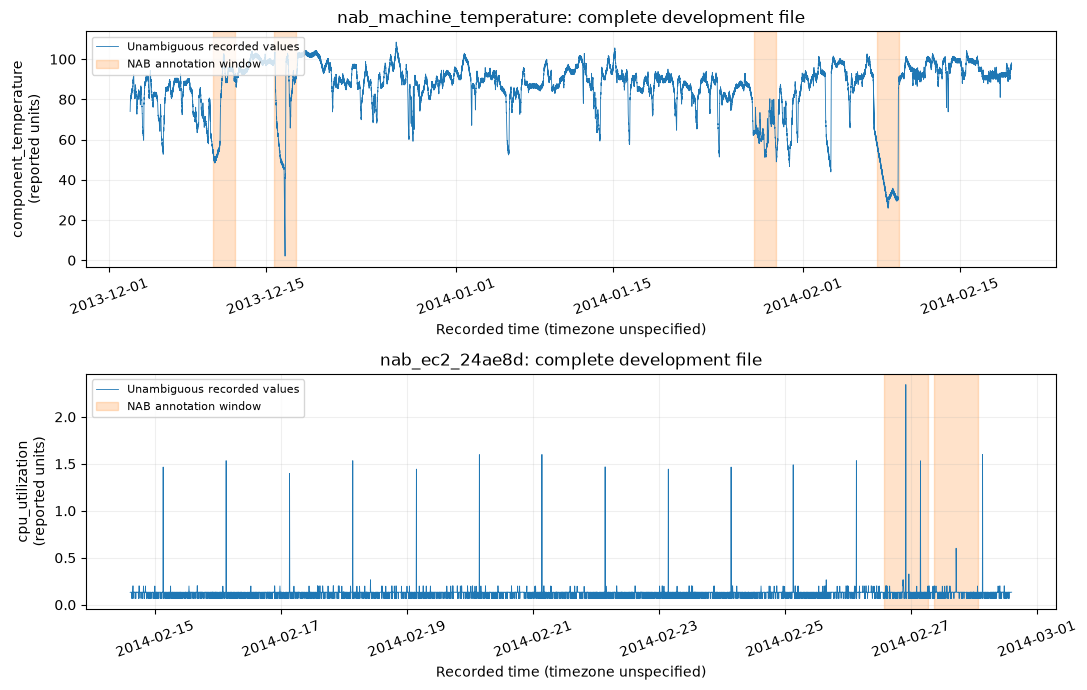

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, ((entity, metric), series) in zip(axes, views.items()):
    ax.plot(series.index, series, linewidth=0.6, label="Unambiguous recorded values")
    events = windows.loc[windows.entity_id.eq(entity)]
    for number, event in enumerate(events.itertuples()):
        ax.axvspan(event.window_start, event.window_end, color="tab:orange", alpha=0.22,
                   label="NAB annotation window" if number == 0 else None)
    ax.set(title=f"{entity}: complete development file", ylabel=f"{metric}\n(reported units)",
           xlabel="Recorded time (timezone unspecified)")
    ax.legend(fontsize=8, loc="upper left")
    ax.tick_params(axis="x", labelrotation=20)
fig.tight_layout()
plt.show()

**Interpretation:** temperature exhibits persistent level changes and large excursions. CPU spends much of the file near a narrow level, with intermittent spikes. Annotation windows are broad relative to individual observations and include measurements that can look ordinary. Neither the raw magnitude nor membership in a window determines whether an operator should receive an alert.

The line breaks at excluded temperature timestamps, although a one-hour gap is difficult to see on a 79-day overview. The audit table gives its exact extent.

## 5. Are the marginal distributions sufficient descriptions?

Quantiles and histograms describe the distribution of observed values. They discard temporal order and combine different operating regimes and annotated periods. They cannot establish normal operating limits. All summaries below use unambiguous finite diagnostic values, with no label-based exclusions.

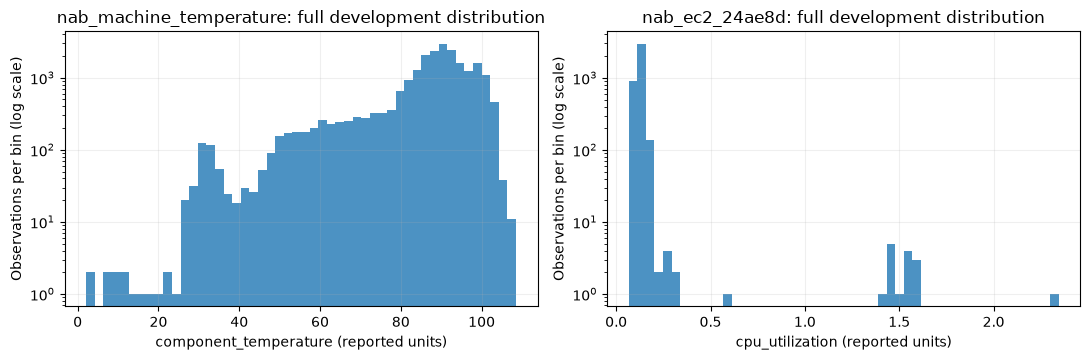

,entity_id,usable_values,minimum,q01,median,q99,maximum
0,nab_machine_temperature,22671,2.0847,32.5241,89.3994,102.9794,108.5105
1,nab_ec2_24ae8d,4032,0.0660,0.0660,0.1340,0.2020,2.3440


In [7]:
distribution_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for ax, ((entity, metric), series) in zip(axes, views.items()):
    values = series.dropna()
    distribution_rows.append({"entity_id": entity, "usable_values": len(values),
        "minimum": values.min(), "q01": values.quantile(.01), "median": values.median(),
        "q99": values.quantile(.99), "maximum": values.max()})
    ax.hist(values, bins=50, color="tab:blue", alpha=0.8)
    ax.set_yscale("log")
    ax.set(title=f"{entity}: full development distribution",
           xlabel=f"{metric} (reported units)", ylabel="Observations per bin (log scale)")
fig.tight_layout()
plt.show()
distributions = pd.DataFrame(distribution_rows)
display(distributions.round(4))

**Finding:** temperature's 1st–99th percentiles are approximately 32.52–102.98 reported units. CPU's are 0.066–0.202, but its maximum is 2.344. A single global mean and variance would mix the central CPU distribution with rare large readings and would mix temperature regimes. These are descriptive findings, not anomaly decisions. The logarithmic count axis makes sparse bins visible; it does not transform the measurements.

## 6. How does the distribution change over time?

Summarise consecutive 24-hour blocks anchored at each file's first timestamp. These are elapsed-time blocks, not verified local calendar days. Display a block only when at least 90% of its 288 assumed slots are usable. This explicit display rule suppresses incomplete blocks; it is not a detector threshold.

The shaded band is the within-block interquartile range, **not a confidence interval**. Changing spread can result from changing regimes, trend or events; it does not by itself prove heteroscedastic measurement noise.

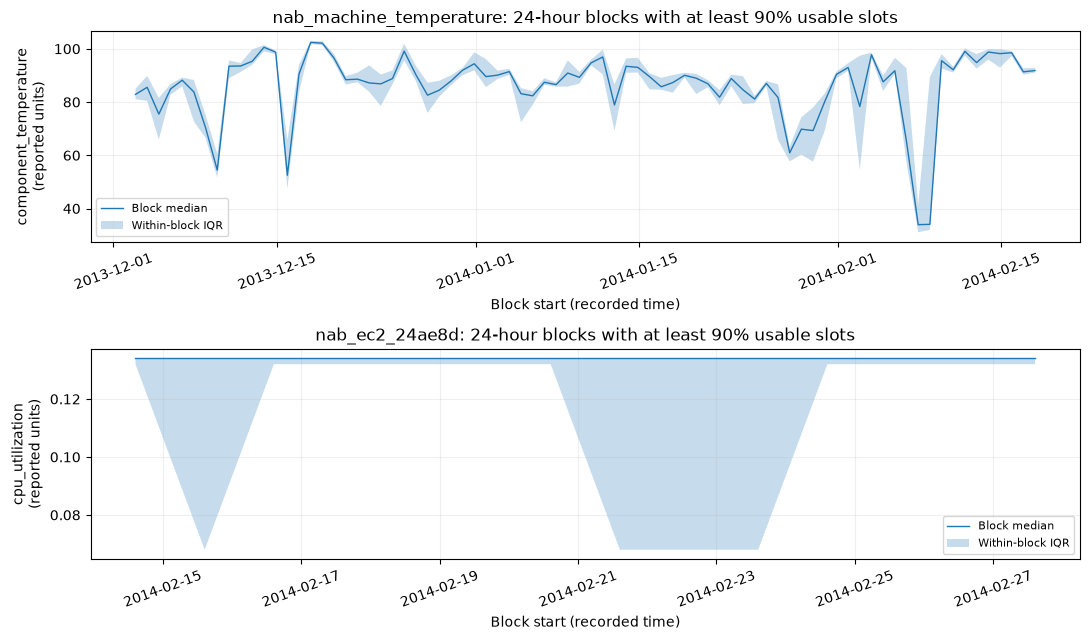

,displayed_blocks,lowest_median,highest_median,smallest_sd,largest_sd
entity_id,,,,,
nab_ec2_24ae8d,14,0.1340,0.1340,0.0816,0.1594
nab_machine_temperature,78,33.9453,102.4117,0.8192,27.8261


In [8]:
block_tables = []
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5))
for ax, ((entity, metric), series) in zip(axes, views.items()):
    blocks = series.resample("24h", origin="start")
    summary = blocks.agg(["count", "median", "std"])
    summary["q25"] = blocks.quantile(.25)
    summary["q75"] = blocks.quantile(.75)
    expected = int(pd.Timedelta("24h") / pd.Timedelta(cadences[(entity, metric)]))
    summary = summary.loc[summary["count"] >= 0.9 * expected]
    block_tables.append(summary.assign(entity_id=entity))
    ax.plot(summary.index, summary["median"], linewidth=1, label="Block median")
    ax.fill_between(summary.index, summary.q25, summary.q75, alpha=.25, label="Within-block IQR")
    ax.set(title=f"{entity}: 24-hour blocks with at least 90% usable slots",
           ylabel=f"{metric}\n(reported units)", xlabel="Block start (recorded time)")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", labelrotation=20)
fig.tight_layout()
plt.show()
block_summary = pd.concat(block_tables)
display(block_summary.groupby("entity_id").agg(
    displayed_blocks=("count", "size"), lowest_median=("median", "min"),
    highest_median=("median", "max"), smallest_sd=("std", "min"), largest_sd=("std", "max")
).round(4))

**Finding:** temperature block medians span approximately 33.95–102.41, and within-block standard deviations range from 0.82 to 27.83. This challenges a single stationary level/scale description. CPU's block median stays at 0.134 while block standard deviations vary; a stable median does not imply that all aspects of the process are stable. The sparse CPU excursions can strongly influence standard deviation.

## 7. How much temporal dependence is visible?

At each elapsed lag, compute Pearson correlation using pairs with finite values at both timestamps, and report the pair count. Never remove missing slots and then treat adjacent retained values as five minutes apart. Compare levels with first differences; differencing is diagnostic here and does not modify the observations.

Correlations at one day or one week are screening evidence, not seasonality tests. Trend, level changes and faults also create autocorrelation. We deliberately omit IID significance bands. Fourteen days of CPU data provide only two weekly cycles, insufficient for a persuasive weekly-pattern assessment.

In [9]:
lag_tables = []
lags = {"5 minutes": "5min", "1 hour": "1h", "1 day": "1D", "1 week": "7D"}
for (entity, metric), series in views.items():
    for representation, values in [("level", series), ("first difference", series.diff())]:
        table = lag_report(values, lags)
        table.insert(0, "representation", representation)
        table.insert(0, "entity_id", entity)
        lag_tables.append(table)
dependence = pd.concat(lag_tables, ignore_index=True)
display(dependence.round(4))

,entity_id,representation,lag,pairs,correlation
0,nab_machine_temperature,level,5 minutes,22669,0.9969
1,nab_machine_temperature,level,1 hour,22647,0.9593
2,nab_machine_temperature,level,1 day,22371,0.3043
3,nab_machine_temperature,level,1 week,20643,-0.0314
4,nab_machine_temperature,first difference,5 minutes,22667,-0.2460
5,nab_machine_temperature,first difference,1 hour,22645,0.0304
6,nab_machine_temperature,first difference,1 day,22368,-0.0032
7,nab_machine_temperature,first difference,1 week,20640,0.0103
8,nab_ec2_24ae8d,level,5 minutes,4031,-0.0401
9,nab_ec2_24ae8d,level,1 hour,4020,-0.0041


**Finding:** the five-minute level correlation is approximately 0.997 for temperature and −0.040 for CPU. Temperature persistence is substantial, but some of it reflects regime shifts and long excursions. CPU's near-zero adjacent correlation does not demonstrate independence or absence of predictable structure. The first-difference comparison helps distinguish level persistence from short-term changes; differencing can itself introduce negative lag-one correlation.

A common algorithm or common smoothing window is therefore not justified simply because both files have five-minute timestamps. Notebook 02 should compare a small set of explicitly chosen baselines separately for each signal.

## 8. Reproducible hand-off and remaining decisions

Save observations and annotations separately. The observation export preserves duplicate timestamps and is named `observations_unresolved` deliberately: it is not model-ready telemetry. The diagnostic views are temporary, explicitly filtered assessment products. Notebook 02 must choose and document its input policy, fit only on past observations and evaluate forecasts or residuals chronologically.

These entire pilot files and their labels have been inspected. Any subsequent within-file validation is **development validation**, not an untouched final test. Before model tuning, specify a separate evaluation set and freeze its role. Other NAB sources have not been downloaded by this workflow. A strong result on NAB will still require independent operational validation.

Before modelling: resolve or explicitly quarantine temperature's conflicting timestamps; define the baseline/adaptation policy; confirm the intended alert meaning; specify fit/calibration/validation windows. Unknown units and timestamps constrain physical thresholds and cross-source comparisons. Neither file establishes failure-prediction lead time.

In [10]:
import platform
from importlib.metadata import version

OUTPUT = ROOT / "outputs/nab_pilot_assessment"
OUTPUT.mkdir(parents=True, exist_ok=True)
observations.to_parquet(OUTPUT / "observations_unresolved.parquet", index=False)
windows.to_parquet(OUTPUT / "benchmark_windows.parquet", index=False)
audit.to_csv(OUTPUT / "data_quality.csv", index=False)
distributions.to_csv(OUTPUT / "distributions.csv", index=False)
dependence.to_csv(OUTPUT / "lag_correlations.csv", index=False)
run_manifest = {
    "source_manifest": manifest,
    "python": platform.python_version(),
    "packages": {name: version(name) for name in ["numpy", "pandas", "matplotlib", "pyarrow", "nbformat", "nbclient"]},
    "diagnostic_policy": "All duplicate timestamps excluded; no filling; raw observations retained.",
    "model_fitted": False,
}
(OUTPUT / "assessment_manifest.json").write_text(json.dumps(run_manifest, indent=2) + "\n")
print("Saved assessment products to", OUTPUT.relative_to(ROOT))
print("No detector or forecast model has been trained. Proceed to Notebook 02 only after its design is agreed.")

Saved assessment products to outputs/nab_pilot_assessment
No detector or forecast model has been trained. Proceed to Notebook 02 only after its design is agreed.


## Sources and evidence

- [NAB official repository](https://github.com/numenta/NAB): corpus and benchmark purpose (maintainer documentation).
- [Pinned source descriptions](https://github.com/numenta/NAB/blob/ea702d75cc2258d9d7dd35ca8e5e2539d71f3140/data/README.md): provenance statements and limited event context.
- [Pinned annotation construction](https://github.com/numenta/NAB/blob/ea702d75cc2258d9d7dd35ca8e5e2539d71f3140/nab/labeler.py): window generation and inclusive endpoint semantics (implementation evidence).
- [Lavin & Ahmad, 2015](https://arxiv.org/abs/1510.03336): NAB's streaming evaluation rationale, IEEE ICMLA conference paper. We have not implemented its scoring protocol here.
- [Forecasting: Principles and Practice, time-series graphics](https://otexts.com/fpp3/graphics.html): descriptive plots, temporal patterns and interpretation of autocorrelation (statistical textbook).
- [AWS CloudWatch EC2 metrics](https://docs.aws.amazon.com/AWSEC2/latest/UserGuide/viewing_metrics_with_cloudwatch.html): standard CPU metric semantics; it does not document the transformation history of this NAB export.

Numerical findings above were calculated from the pinned files. Passing schema/checksum checks establishes consistency, not authenticity, complete labels or suitability for every industry.